# Predicción del éxito comercial de películas
## Proyecto integrador del Bloque 2 de Machine Learning

**Pregunta:** ¿Qué modelo ofrece el mejor equilibrio entre capacidad de clasificación,
costo computacional e interpretabilidad para anticipar el desempeño en taquilla?

Se comparan SVM, Árbol de Decisión, Random Forest (Bagging) y Gradient Boosting
sobre las mismas películas y particiones. Gradient Boosting es una opción admitida
por la rúbrica; no se necesita XGBoost para cumplir el criterio de Boosting.

**Objetivo operativo:** clase 1 si `revenue >= 2 * budget`, clase 0 en caso contrario.
El umbral es una aproximación explícita al desempeño comercial, no una medición
de rentabilidad contable. No conocemos todos los gastos ni la parte de la taquilla
que recibe el estudio. El valor 2 se fija antes de entrenar, no buscando mejores métricas.

**Objetivos medibles:** comparar accuracy, precisión, recall, F1, F1 macro y ROC-AUC;
medir entrenamiento y predicción; explicar errores e importancia de variables.

**Uso:** colocar este notebook junto a los dos CSV y ejecutar todas las celdas en orden.
En Colab, subir ambos CSV a `/content`. Los resultados se guardan en `resultados/`.


## 1. Entorno y reproducibilidad
Si faltan dependencias, ejecutar en una celda aparte:
`%pip install pandas numpy scikit-learn matplotlib`
Luego reiniciar el kernel y ejecutar desde el comienzo. No instalar durante la medición.
Los tiempos dependen del equipo y las versiones; no comparar ejecuciones en equipos distintos.


In [1]:
from pathlib import Path
import json, platform, sys, time, hashlib, bisect, importlib.metadata
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay, classification_report)
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits
threadpool_controller = threadpool_limits(limits=1)

SEED = 42
THRESHOLD = 2.0
TEST_SIZE = 0.20
N_SPLITS = 3
N_REPEATS = 3
F1_TOLERANCE = 0.01
BASE = Path.cwd()
candidates = [BASE, BASE/'dataset', BASE/'Proyecto-Integrador',
              BASE/'Proyecto-Integrador/dataset', Path('/content')]
DATA_DIR = next((folder for folder in candidates
                 if all((folder/f).exists() for f in ['tmdb_5000_movies.csv','tmdb_5000_credits.csv'])), None)
if DATA_DIR is None:
    raise FileNotFoundError(f'No se encuentran ambos CSV desde {BASE}. Colocarlos junto al notebook o en dataset/.')
print('Carpeta de datos:', DATA_DIR)
OUT = BASE / 'resultados'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
environment = {'python': sys.version, 'platform': platform.platform(), 'processor': platform.processor(),
               'versions': {p: importlib.metadata.version(p) for p in ['pandas','numpy','scikit-learn','matplotlib']},
               'seed': SEED, 'cv_folds': N_SPLITS, 'benchmark_repetitions': N_REPEATS,
               'threads': 'Estimadores y búsqueda con n_jobs=1; bibliotecas numéricas limitadas a un hilo con threadpoolctl.'}
display(environment)


Carpeta de datos: C:\Users\Usuario\Documents\UCB-SW\SEM6\MachineLearning\ML-Bloque2\Proyecto-Integrador\Proyecto-Integrador\dataset


{'python': '3.12.14 (main, Aug 25 2026, 14:01:42) [MSC v.1944 64 bit (AMD64)]',
 'platform': 'Windows-11-10.0.26200-SP0',
 'processor': 'Intel64 Family 6 Model 154 Stepping 3, GenuineIntel',
 'versions': {'pandas': '3.0.5',
  'numpy': '2.5.2',
  'scikit-learn': '1.9.0',
  'matplotlib': '3.11.1'},
 'seed': 42,
 'cv_folds': 3,
 'benchmark_repetitions': 3,
 'threads': 'Estimadores y búsqueda con n_jobs=1; bibliotecas numéricas limitadas a un hilo con threadpoolctl.'}

## 2. Carga y control de calidad
La unión debe ser uno a uno. No se eliminan filas por carecer de página web o sinopsis,
porque esas columnas no se usan. Presupuesto o recaudación en cero se consideran
información insuficiente para etiquetar; no se imputan para inventar el resultado.


In [2]:
movies = pd.read_csv(DATA_DIR / 'tmdb_5000_movies.csv')
credits = pd.read_csv(DATA_DIR / 'tmdb_5000_credits.csv')
assert not movies['id'].duplicated().any(), 'IDs duplicados en películas.'
assert not credits['movie_id'].duplicated().any(), 'IDs duplicados en créditos.'
assert set(movies['id']) == set(credits['movie_id']), 'Películas sin créditos o IDs adicionales.'
raw = movies.merge(credits.drop(columns='title'), left_on='id', right_on='movie_id', validate='one_to_one')
quality = pd.DataFrame({'nulos': raw.isna().sum(),
                        'porcentaje_nulos': raw.isna().mean().mul(100).round(2)})
display(quality)
valid = raw['budget'].gt(0) & raw['revenue'].gt(0)
data = raw.loc[valid].copy()
data['release_date'] = pd.to_datetime(data['release_date'], errors='coerce')
data = data.loc[data['release_date'].notna()].copy()
data['runtime'] = data['runtime'].where(data['runtime'].gt(0), np.nan)
data['exito'] = data['revenue'].ge(THRESHOLD * data['budget']).astype(int)
assert data['exito'].nunique() == 2
audit = {'peliculas_originales': len(movies), 'creditos_originales': len(credits),
         'presupuesto_cero': int(movies.budget.eq(0).sum()),
         'recaudacion_cero': int(movies.revenue.eq(0).sum()),
         'filas_utilizables': len(data), 'filas_excluidas': len(raw)-len(data),
         'clases': {str(k): int(v) for k,v in data.exito.value_counts().sort_index().items()},
         'umbral': THRESHOLD, 'fecha_min': str(data.release_date.min().date()),
         'fecha_max': str(data.release_date.max().date())}
environment['sha256'] = {f: hashlib.sha256((DATA_DIR/f).read_bytes()).hexdigest()
    for f in ['tmdb_5000_movies.csv','tmdb_5000_credits.csv']}
display(audit)
quality.to_csv(OUT/'calidad_datos.csv', index_label='variable')


,nulos,porcentaje_nulos
budget,0,0.00
genres,0,0.00
homepage,3091,64.36
id,0,0.00
keywords,0,0.00
original_language,0,0.00
original_title,0,0.00
overview,3,0.06
popularity,0,0.00
production_companies,0,0.00


{'peliculas_originales': 4803,
 'creditos_originales': 4803,
 'presupuesto_cero': 1037,
 'recaudacion_cero': 1427,
 'filas_utilizables': 3229,
 'filas_excluidas': 1574,
 'clases': {'0': 1420, '1': 1809},
 'umbral': 2.0,
 'fecha_min': '1916-09-04',
 'fecha_max': '2016-09-09'}

## 3. Variables disponibles antes del estreno
Se usan presupuesto, duración, año y mes de estreno, idioma, país de producción,
géneros y trayectoria del elenco/directores. Se asume que presupuesto, duración
y fecha de estreno están disponibles en la planificación; los CSV históricos no
certifican sus valores exactos en ese momento.

Se excluyen `revenue` como predictor, cualquier cociente que la contenga,
`vote_average`, `vote_count` y `popularity`. La recaudación solo construye la etiqueta.
Títulos, sinopsis e identificadores de películas tampoco entran al modelo.

**Trayectoria no significa popularidad:** se cuenta cuántas películas anteriores de
cada actor/director aparecen en el entrenamiento. Se ajusta dentro de cada fold,
solo considera fechas estrictamente anteriores y no utiliza éxitos ni recaudaciones.
La cobertura de esta colección es parcial y no equivale a toda su filmografía.


In [3]:
def parse_list(value):
    return json.loads(value) if isinstance(value, str) else []

X = pd.DataFrame(index=data.index)
X['budget'] = data.budget
X['runtime'] = data.runtime
X['release_date'] = data.release_date
X['release_year'] = data.release_date.dt.year
X['release_month'] = data.release_date.dt.month.astype(str)
X['original_language'] = data.original_language.fillna('desconocido')
X['country'] = data.production_countries.map(lambda s: (parse_list(s)[0]['iso_3166_1']
    if parse_list(s) else 'desconocido'))
X['genre_tokens'] = data.genres.map(lambda s: ' '.join('g'+str(g['id']) for g in parse_list(s)))
X['cast_ids'] = data.cast.map(lambda s: tuple(int(a['id']) for a in parse_list(s)[:5]))
X['director_ids'] = data.crew.map(lambda s: tuple(int(a['id']) for a in parse_list(s) if a['job']=='Director'))
y = data.exito
assert not {'revenue','popularity','vote_average','vote_count','exito'}.intersection(X.columns)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE,
                                                stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
split_manifest = pd.DataFrame({'id': data.id, 'conjunto': np.where(data.index.isin(X_train.index),
                                                               'entrenamiento','prueba')})
split_manifest.to_csv(OUT/'particion.csv', index=False)
display(pd.DataFrame({'entrenamiento': y_train.value_counts().sort_index(),
                      'prueba': y_test.value_counts().sort_index()}))


,entrenamiento,prueba
exito,,
0,1136,284
1,1447,362


## 4. Análisis estadístico sobre entrenamiento
Las decisiones de preprocesamiento y ajuste se toman sin explorar los resultados
de prueba. Se interpretan distribuciones, valores extremos y correlaciones.
No se eliminan grandes presupuestos por ser outliers: son películas válidas.
La transformación `log1p` reduce su asimetría sin recortar información.


,count,mean,std,min,25%,50%,75%,max
budget,2583.0,4.123936e+07,4.440694e+07,1.0,11000000.0,26000000.0,55000000.0,3.800000e+08
revenue,2583.0,1.215945e+08,1.845420e+08,7.0,17503684.0,57223890.0,144136670.5,2.787965e+09
runtime,2583.0,1.109051e+02,2.107219e+01,41.0,96.0,107.0,121.0,3.380000e+02


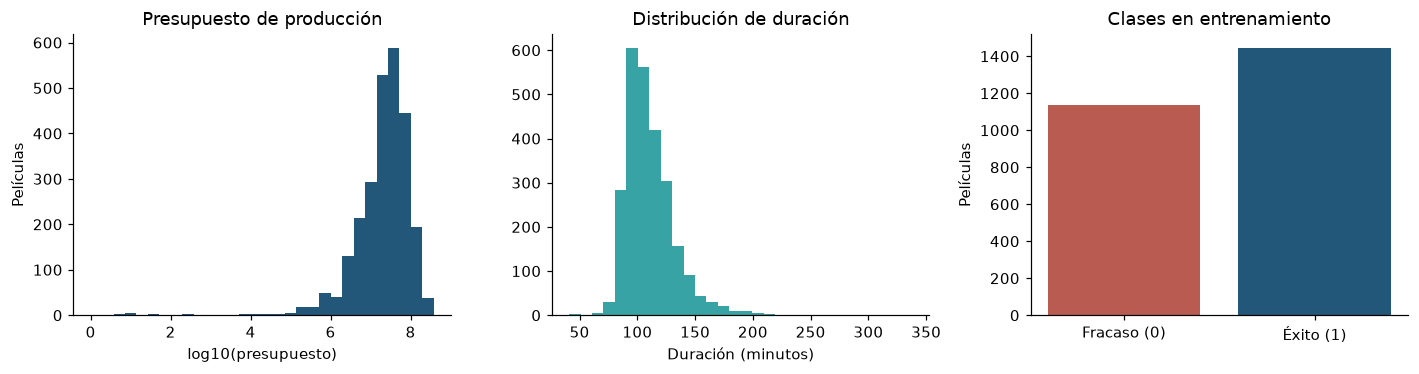

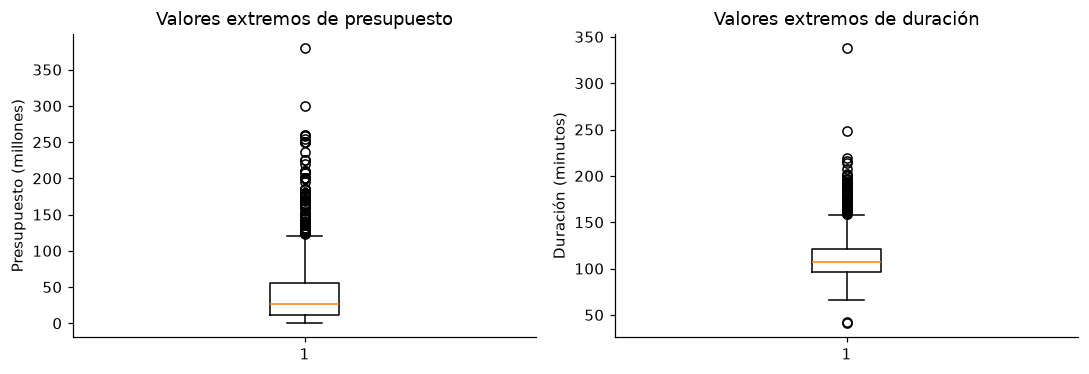

,log_presupuesto,duracion,anio,log_recaudacion,exito
log_presupuesto,1.000000,0.231662,0.221424,0.682503,-0.057023
duracion,0.231662,1.000000,-0.081448,0.225074,0.045080
anio,0.221424,-0.081448,1.000000,0.139899,-0.052774
log_recaudacion,0.682503,0.225074,0.139899,1.000000,0.521488
exito,-0.057023,0.045080,-0.052774,0.521488,1.000000


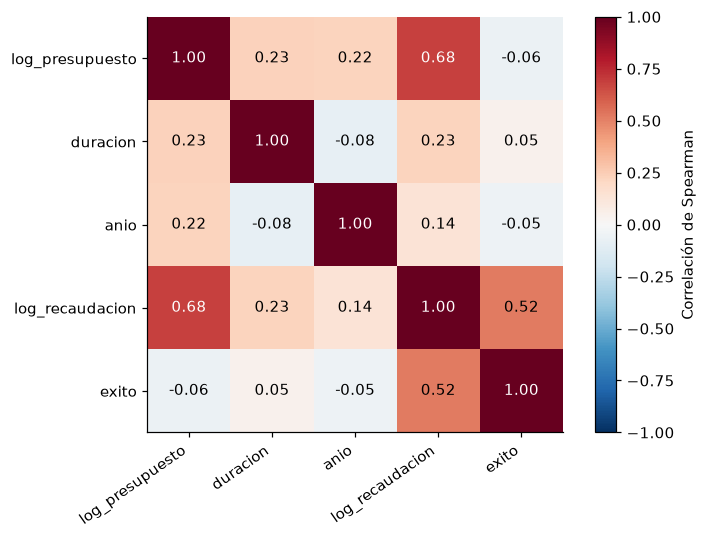

La recaudación aparece aquí solo para describir el fenómeno: **no es predictor**. La correlación con la etiqueta incluye su relación matemática y no demuestra causalidad. La clase mayoritaria representa 56.0% del entrenamiento.

In [4]:
train_data = data.loc[X_train.index]
descriptive = train_data[['budget','revenue','runtime']].describe().T
display(descriptive)
descriptive.to_csv(OUT/'estadistica_descriptiva.csv')
fig, axes = plt.subplots(1,3,figsize=(13,3.5))
axes[0].hist(np.log10(train_data.budget),bins=30,color='#22577a')
axes[0].set(xlabel='log10(presupuesto)',ylabel='Películas',title='Presupuesto de producción')
axes[1].hist(train_data.runtime.dropna(),bins=30,color='#38a3a5')
axes[1].set(xlabel='Duración (minutos)',title='Distribución de duración')
counts=y_train.value_counts().sort_index()
axes[2].bar(['Fracaso (0)','Éxito (1)'],counts,color=['#b95b50','#22577a'])
axes[2].set(ylabel='Películas',title='Clases en entrenamiento')
fig.tight_layout(); fig.savefig(OUT/'01_distribuciones.png',dpi=180); plt.show()

fig,axes=plt.subplots(1,2,figsize=(10,3.5))
axes[0].boxplot(train_data.budget/1e6); axes[0].set(ylabel='Presupuesto (millones)',title='Valores extremos de presupuesto')
axes[1].boxplot(train_data.runtime.dropna()); axes[1].set(ylabel='Duración (minutos)',title='Valores extremos de duración')
fig.tight_layout(); fig.savefig(OUT/'02_outliers.png',dpi=180); plt.show()

correlation = pd.DataFrame({'log_presupuesto': np.log1p(train_data.budget),
    'duracion': train_data.runtime,'anio': train_data.release_date.dt.year,
    'log_recaudacion': np.log1p(train_data.revenue),'exito': y_train}).corr(method='spearman')
display(correlation)
fig,ax=plt.subplots(figsize=(7,5)); im=ax.imshow(correlation,vmin=-1,vmax=1,cmap='RdBu_r')
ax.set_xticks(range(len(correlation)),correlation.columns,rotation=35,ha='right')
ax.set_yticks(range(len(correlation)),correlation.index)
for i in range(len(correlation)):
    for j in range(len(correlation)):
        ax.text(j,i,f'{correlation.iloc[i,j]:.2f}',ha='center',va='center',
                color='white' if abs(correlation.iloc[i,j])>.6 else 'black')
fig.colorbar(im,ax=ax,label='Correlación de Spearman');fig.tight_layout()
fig.savefig(OUT/'03_correlacion.png',dpi=180);plt.show()
correlation.to_csv(OUT/'correlacion.csv')
display(Markdown('La recaudación aparece aquí solo para describir el fenómeno: **no es predictor**. '
    'La correlación con la etiqueta incluye su relación matemática y no demuestra causalidad. '
    f'La clase mayoritaria representa {y_train.value_counts(normalize=True).max():.1%} del entrenamiento.'))


## 5. Preprocesamiento dentro de cada fold
La imputación y codificación se aprenden dentro de cada entrenamiento mediante
`Pipeline`. SVM escala las variables numéricas; los árboles no necesitan esa escala.
El idioma y país poco frecuentes se agrupan; los géneros se codifican como presencia
o ausencia, preservando películas con múltiples géneros. El mes es categórico,
porque diciembre no debe tratarse como doce veces enero.


In [5]:
class HistoricalFeatures(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.histories_ = {'cast_ids': defaultdict(list), 'director_ids': defaultdict(list)}
        for field, histories in self.histories_.items():
            for ids, date in zip(X[field], X.release_date):
                for person in set(ids):
                    histories[person].append(pd.Timestamp(date).value)
            for dates in histories.values():
                dates.sort()
        return self

    def transform(self, X):
        frame = X.copy()
        frame['log_budget'] = np.log1p(frame.budget)
        for field, output in [('cast_ids','cast_experience'),('director_ids','director_experience')]:
            histories = self.histories_[field]
            frame[output] = [np.log1p(np.mean([bisect.bisect_left(histories.get(p, []),
                            pd.Timestamp(date).value) for p in set(ids)])) if ids else 0.0
                for ids, date in zip(X[field], X.release_date)]
        return frame

numeric = ['log_budget','runtime','release_year','cast_experience','director_experience']
categorical = ['release_month','original_language','country']
def make_pipeline(model, scale=False):
    steps = [('imputer',SimpleImputer(strategy='median'))]
    if scale:
        steps.append(('scale',StandardScaler()))
    preprocess = ColumnTransformer([
        ('numeric',Pipeline(steps),numeric),
        ('categorical',OneHotEncoder(handle_unknown='ignore',min_frequency=20,sparse_output=False),categorical),
        ('genres',CountVectorizer(binary=True,token_pattern=r'g\d+'), 'genre_tokens')
    ], sparse_threshold=0,verbose_feature_names_out=True)
    return Pipeline([('history',HistoricalFeatures()),('preprocess',preprocess),('model',model)])

def tune(name, estimator, grid):
    search = GridSearchCV(estimator,grid,scoring='f1_macro',cv=cv,n_jobs=1,
                          refit=True,return_train_score=True,error_score='raise')
    start=time.perf_counter(); search.fit(X_train,y_train)
    elapsed=time.perf_counter()-start
    frame=pd.DataFrame(search.cv_results_)
    frame.to_csv(OUT/f'cv_{name}.csv',index=False)
    print(name, 'F1 macro CV:',round(search.best_score_,4),'parámetros:',search.best_params_,
          'búsqueda (s):',round(elapsed,2))
    return search, elapsed

searches={}; search_times={}


## 6. SVM no lineal
Se utiliza kernel RBF para relaciones no lineales sin definir manualmente interacciones.
Se ajustan C (penalización/regularización) y gamma (alcance de cada observación).
`probability=False` evita el costo extra de calibración; ROC-AUC admite decision scores.


In [6]:
searches['SVM'],search_times['SVM']=tune('SVM',make_pipeline(SVC(kernel='rbf'),scale=True),
    {'model__C':[0.1,1,10], 'model__gamma':['scale',0.01,0.1]})


SVM F1 macro CV: 0.5855 parámetros: {'model__C': 1, 'model__gamma': 'scale'} búsqueda (s): 58.1


## 7. Árbol de Decisión
Gini y entropía miden impureza. Profundidad máxima y mínimo de muestras por hoja
limitan el sobreajuste. La brecha entre F1 de entrenamiento y validación permite
discutir varianza; la importancia no implica que una variable cause éxito.


In [7]:
searches['Arbol'],search_times['Arbol']=tune('Arbol',make_pipeline(DecisionTreeClassifier(random_state=SEED)),
    {'model__criterion':['gini','entropy'], 'model__max_depth':[3,6,None],
     'model__min_samples_leaf':[5,20]})


Arbol F1 macro CV: 0.575 parámetros: {'model__criterion': 'gini', 'model__max_depth': None, 'model__min_samples_leaf': 20} búsqueda (s): 23.58


## 8. Bagging con Random Forest
Random Forest combina árboles entrenados con muestras bootstrap y subconjuntos
de variables, reduciendo la varianza. Se ajustan cantidad de árboles, profundidad
y mínimo de muestras por hoja. OOB es un diagnóstico adicional del bosque;
no sustituye la evaluación de todo el pipeline mediante validación cruzada.


In [8]:
searches['RandomForest'],search_times['RandomForest']=tune('RandomForest',
    make_pipeline(RandomForestClassifier(random_state=SEED,bootstrap=True,oob_score=True,n_jobs=1)),
    {'model__n_estimators':[150,300], 'model__max_depth':[8,None], 'model__min_samples_leaf':[2,8]})
print('Accuracy OOB:',searches['RandomForest'].best_estimator_.named_steps['model'].oob_score_)


RandomForest F1 macro CV: 0.6005 parámetros: {'model__max_depth': None, 'model__min_samples_leaf': 2, 'model__n_estimators': 300} búsqueda (s): 59.48
Accuracy OOB: 0.6159504452187379


## 9. Boosting con Gradient Boosting
Los árboles se agregan secuencialmente para reducir los errores del conjunto.
Se ajustan learning_rate, profundidad y máximo de estimadores. La parada temprana
usa un 20% interno del entrenamiento; jamás utiliza el conjunto de prueba.
`n_iter_no_change=15` y `tol=0.001` detienen la incorporación de árboles cuando
la pérdida de validación interna deja de mejorar. Se informa la cantidad efectiva.


In [9]:
searches['Boosting'],search_times['Boosting']=tune('Boosting',
    make_pipeline(GradientBoostingClassifier(random_state=SEED,n_iter_no_change=15,
                                            validation_fraction=.2,tol=.001,min_samples_leaf=10)),
    {'model__learning_rate':[0.03,0.1], 'model__n_estimators':[200,400], 'model__max_depth':[2,3]})
print('Árboles efectivos:',searches['Boosting'].best_estimator_.named_steps['model'].n_estimators_)


Boosting F1 macro CV: 0.5769 parámetros: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200} búsqueda (s): 34.68
Árboles efectivos: 49


## 10. Costo y selección antes de evaluar prueba
**Criterio fijado previamente:** maximizar F1 macro en validación cruzada, para dar
peso a ambas clases. Entre modelos a no más de 0.01 del mejor F1 macro de CV,
se elige el de menor mediana de tiempo de entrenamiento. Es una preferencia
operativa, no una prueba de equivalencia estadística.

Se mide el entrenamiento del pipeline completo y la predicción de clases del lote
de prueba. Se reportan medianas de tres repeticiones y tiempo por película; la
búsqueda de hiperparámetros se informa aparte. Se hace un calentamiento antes
de medir inferencia. ROC-AUC y gráficos no forman parte del tiempo de predicción.
La selección se realiza antes de observar las métricas de prueba.


In [10]:
models={}; costs={}; cv_rows=[]
for name,search in searches.items():
    fit_seconds=[]
    for repeat in range(N_REPEATS):
        fitted=clone(search.best_estimator_)
        start=time.perf_counter();fitted.fit(X_train,y_train)
        fit_seconds.append(time.perf_counter()-start)
    models[name]=fitted
    fitted.predict(X_test)  # Calentamiento; no calcular métricas para seleccionar.
    pred_seconds=[]
    for repeat in range(N_REPEATS):
        start=time.perf_counter();fitted.predict(X_test)
        pred_seconds.append(time.perf_counter()-start)
    costs[name]={'entrenamiento_s':float(np.median(fit_seconds)),
                 'prediccion_lote_s':float(np.median(pred_seconds)),
                 'prediccion_por_pelicula_ms':float(np.median(pred_seconds)*1000/len(X_test)),
                 'busqueda_s':search_times[name], 'entrenamientos_s':fit_seconds,
                 'predicciones_s':pred_seconds}
    idx=search.best_index_
    cv_rows.append({'modelo':name,'f1_macro_cv':search.best_score_,
                    'desv_cv':float(search.cv_results_['std_test_score'][idx]),
                    'f1_macro_train_cv':float(search.cv_results_['mean_train_score'][idx]),
                    'brecha_train_cv':float(search.cv_results_['mean_train_score'][idx]-search.best_score_),
                    'entrenamiento_s':costs[name]['entrenamiento_s']})
cv_summary=pd.DataFrame(cv_rows).set_index('modelo')
eligible=cv_summary[cv_summary.f1_macro_cv >= cv_summary.f1_macro_cv.max()-F1_TOLERANCE]
selected=eligible.entrenamiento_s.idxmin()
display(cv_summary)
print('Modelo seleccionado antes de evaluar prueba:',selected)
cv_summary.to_csv(OUT/'resumen_validacion.csv')


Modelo seleccionado antes de evaluar prueba: RandomForest


,f1_macro_cv,desv_cv,f1_macro_train_cv,brecha_train_cv,entrenamiento_s
modelo,,,,,
SVM,0.585494,0.007574,0.727767,0.142273,1.432651
Arbol,0.575050,0.020091,0.688981,0.113931,0.359314
RandomForest,0.600485,0.009942,0.979288,0.378803,3.836793
Boosting,0.576882,0.007724,0.703885,0.127003,0.461219


## 11. Evaluación final común y referencia mínima
Los cuatro modelos se evalúan sobre la misma prueba reservada, sin reajustarlos
con sus resultados. Precisión, recall y F1 corresponden a éxito (clase 1).
F1 macro promedia F1 de éxito y fracaso. ROC-AUC se calcula con probabilidades
o decision scores, nunca con las etiquetas binarias predichas.
DummyClassifier predice siempre la clase mayoritaria y permite verificar si los
modelos aportan valor. El ganador de prueba se puede describir, pero no cambia
la selección previamente realizada por CV y costo.


In [11]:
def metrics(estimator, features, target):
    predicted=estimator.predict(features)
    score=estimator.decision_function(features) if hasattr(estimator,'decision_function') else estimator.predict_proba(features)[:,1]
    return {'accuracy':accuracy_score(target,predicted),
            'precision':precision_score(target,predicted,zero_division=0),
            'recall':recall_score(target,predicted,zero_division=0),
            'f1':f1_score(target,predicted,zero_division=0),
            'f1_macro':f1_score(target,predicted,average='macro',zero_division=0),
            'roc_auc':roc_auc_score(target,score)}

rows=[]
for name,model in models.items():
    record={'modelo':name,**metrics(model,X_test,y_test)}
    record.update({k:costs[name][k] for k in ['entrenamiento_s','prediccion_lote_s',
                                           'prediccion_por_pelicula_ms','busqueda_s']})
    record['f1_macro_cv']=searches[name].best_score_
    rows.append(record)
comparison=pd.DataFrame(rows).set_index('modelo')
dummy=DummyClassifier(strategy='most_frequent').fit(np.zeros((len(y_train),1)),y_train)
baseline=metrics(dummy,np.zeros((len(y_test),1)),y_test)
display(comparison.round(4));display(pd.Series(baseline,name='Dummy mayoritario'))
comparison.to_csv(OUT/'comparacion_modelos.csv')
predictions=pd.DataFrame({'id':data.loc[X_test.index,'id'],'real':y_test})
for name,model in models.items():predictions[name]=model.predict(X_test)
predictions.to_csv(OUT/'predicciones_prueba.csv',index=False)
print(classification_report(y_test,models[selected].predict(X_test),target_names=['Fracaso','Éxito'],zero_division=0))


              precision    recall  f1-score   support

     Fracaso       0.59      0.51      0.55       284
       Éxito       0.65      0.73      0.69       362

    accuracy                           0.63       646
   macro avg       0.62      0.62      0.62       646
weighted avg       0.63      0.63      0.63       646



,accuracy,precision,recall,f1,f1_macro,roc_auc,entrenamiento_s,prediccion_lote_s,prediccion_por_pelicula_ms,busqueda_s,f1_macro_cv
modelo,,,,,,,,,,,
SVM,0.6610,0.6757,0.7597,0.7152,0.6482,0.6997,1.4327,0.3999,0.6191,58.0993,0.5855
Arbol,0.5759,0.6236,0.6133,0.6184,0.5705,0.5878,0.3593,0.0705,0.1091,23.5786,0.5750
RandomForest,0.6300,0.6526,0.7265,0.6876,0.6170,0.6870,3.8368,0.0942,0.1458,59.4793,0.6005
Boosting,0.6424,0.6601,0.7459,0.7004,0.6285,0.6819,0.4612,0.0270,0.0418,34.6808,0.5769


accuracy     0.560372
precision    0.560372
recall       1.000000
f1           0.718254
f1_macro     0.359127
roc_auc      0.500000
Name: Dummy mayoritario, dtype: float64

## 12. Gráficos e interpretación
La matriz de confusión del modelo seleccionado distingue películas exitosas
predichas como fracasos (oportunidades perdidas) y fracasos predichos como éxitos
(decisiones de inversión equivocadas). No se asigna aquí un costo monetario inventado.

La importancia del árbol se agrega por variable original: sumar géneros evita
comparar una columna numérica con cada género por separado. Puede favorecer
variables con más posibilidades de división; la importancia por permutación del
modelo seleccionado es una comprobación adicional. Se interpreta asociación,
no causalidad, y no se reajusta tras inspeccionar la prueba.


|--- numeric__release_year <= 1992.50
|   |--- numeric__log_budget <= 16.56
|   |   |--- numeric__release_year <= 1964.50
|   |   |   |--- numeric__release_year <= 1954.50
|   |   |   |   |--- class: 1
|   |   |   |--- numeric__release_year >  1954.50
|   |   |   |   |--- class: 1
|   |   |--- numeric__release_year >  1964.50
|   |   |   |--- genres__g878 <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- genres__g878 >  0.50
|   |   |   |   |--- class: 1
|   |--- numeric__log_budget >  16.56
|   |   |--- numeric__cast_experience <= 0.40
|   |   |   |--- numeric__runtime <= 128.00
|   |   |   |   |--- class: 0
|   |   |   |--- numeric__runtime >  128.00
|   |   |   |   |--- class: 1
|   |   |--- numeric__cast_experience >  0.40
|   |   |   |--- numeric__log_budget <= 17.06
|   |   |   |   |--- class: 1
|   |   |   |--- numeric__log_budget >  17.06
|   |   |   |   |--- truncated branch of depth 2
|--- numeric__release_year >  1992.50
|   |--- numeric__log_budget <

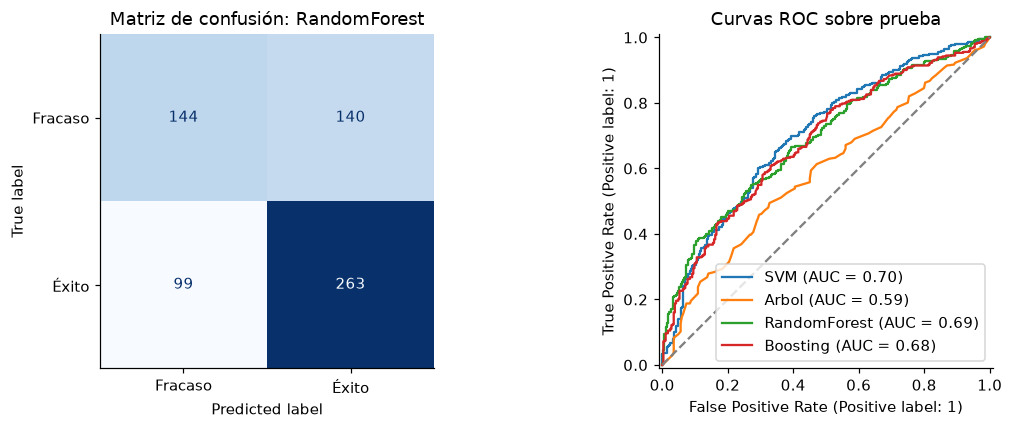

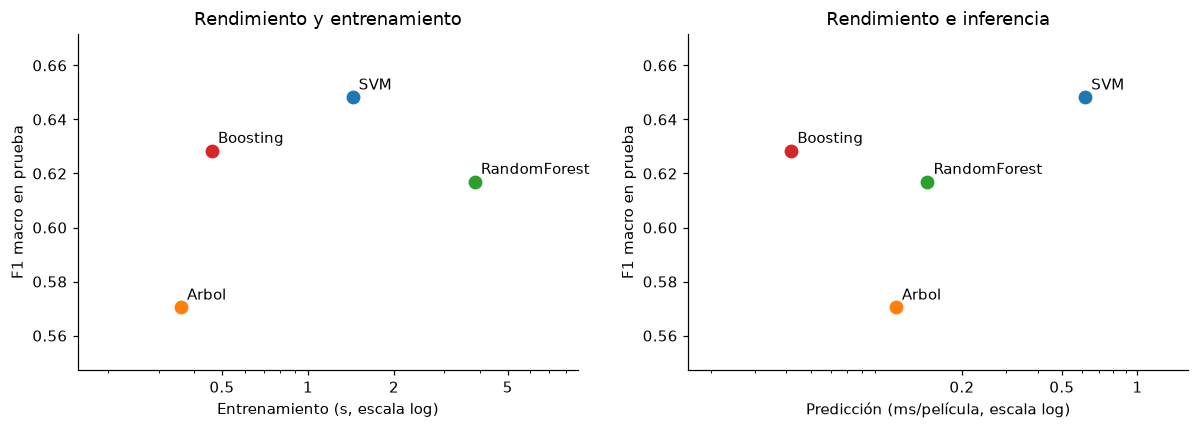

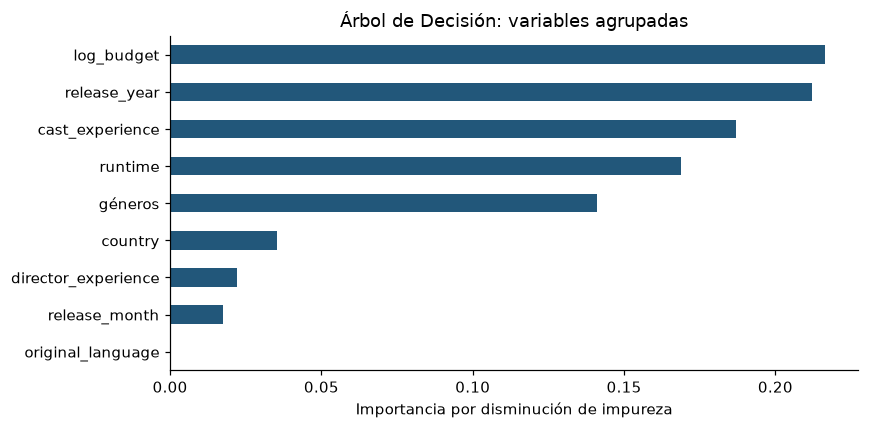

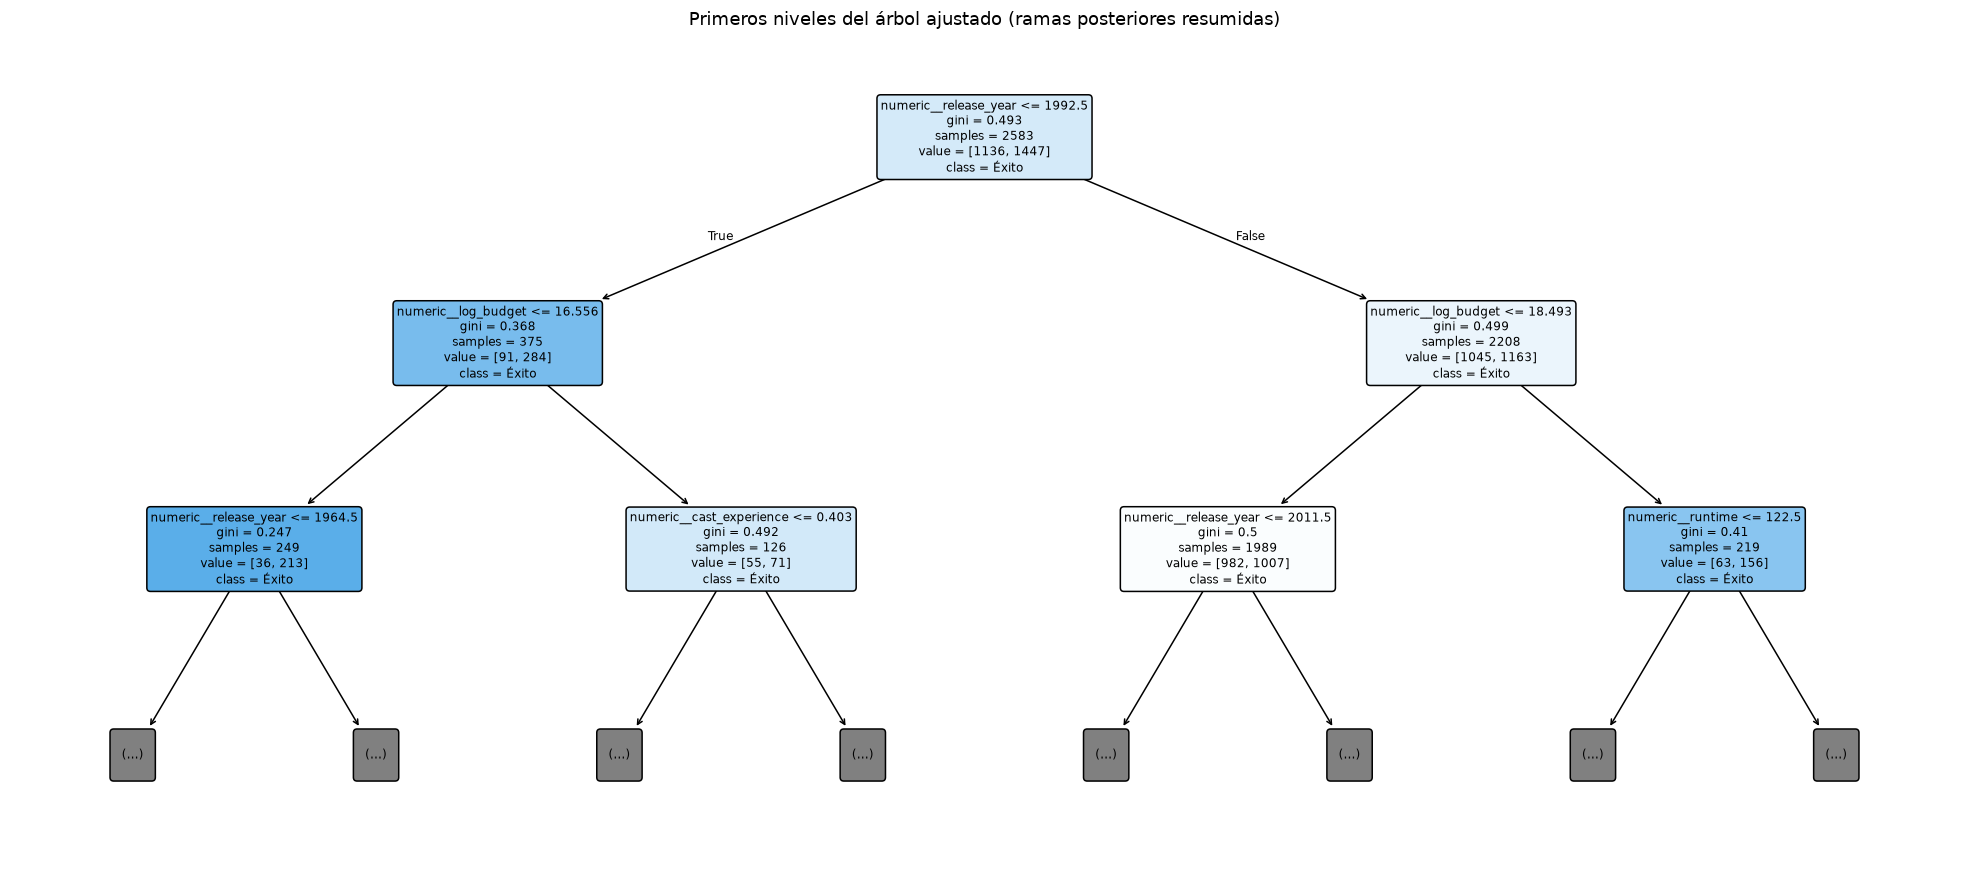

,variable,media,desv
5,géneros,0.037514,0.017441
2,fecha de estreno,0.026366,0.018605
0,presupuesto,0.014877,0.014468
4,país,0.013832,0.010344
1,duración,0.007539,0.004124
3,idioma,-0.001075,0.001863
6,elenco,-0.002969,0.010361
7,dirección,-0.006109,0.004852


In [12]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
ConfusionMatrixDisplay.from_estimator(models[selected],X_test,y_test,
    display_labels=['Fracaso','Éxito'],cmap='Blues',colorbar=False,ax=axes[0])
axes[0].set_title(f'Matriz de confusión: {selected}')
for name,model in models.items():RocCurveDisplay.from_estimator(model,X_test,y_test,name=name,ax=axes[1])
axes[1].plot([0,1],[0,1],'--',color='gray');axes[1].set_title('Curvas ROC sobre prueba')
fig.tight_layout();fig.savefig(OUT/'04_evaluacion.png',dpi=180);plt.show()

fig,axes=plt.subplots(1,2,figsize=(11,4))
for name,row in comparison.iterrows():
    axes[0].scatter(row.entrenamiento_s,row.f1_macro,s=65);axes[0].annotate(name,(row.entrenamiento_s,row.f1_macro),xytext=(4,5),textcoords='offset points')
    axes[1].scatter(row.prediccion_por_pelicula_ms,row.f1_macro,s=65);axes[1].annotate(name,(row.prediccion_por_pelicula_ms,row.f1_macro),xytext=(4,5),textcoords='offset points')
axes[0].set(xlabel='Entrenamiento (s, escala log)',ylabel='F1 macro en prueba',title='Rendimiento y entrenamiento',xscale='log')
axes[1].set(xlabel='Predicción (ms/película, escala log)',ylabel='F1 macro en prueba',title='Rendimiento e inferencia',xscale='log')
from matplotlib.ticker import NullFormatter
axes[0].set_xticks([0.5,1,2,5,10],labels=['0.5','1','2','5','10'])
axes[1].set_xticks([0.2,0.5,1,2],labels=['0.2','0.5','1','2'])
for ax in axes:
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.margins(x=.35,y=.3)
fig.tight_layout();fig.savefig(OUT/'05_rendimiento_costo.png',dpi=180);plt.show()

tree= models['Arbol']
feature_names=tree.named_steps['preprocess'].get_feature_names_out()
importance=pd.Series(tree.named_steps['model'].feature_importances_,index=feature_names)
def group_feature(name):
    if name.startswith('genres__'):return 'géneros'
    if name.startswith('categorical__'):
        for col in categorical:
            if name.startswith('categorical__'+col+'_'):return col
    return name.replace('numeric__','')
grouped=importance.groupby([group_feature(n) for n in importance.index]).sum().sort_values()
grouped.to_csv(OUT/'importancia_arbol.csv',header=['importancia'])
fig,ax=plt.subplots(figsize=(8,4));grouped.plot.barh(ax=ax,color='#22577a')
ax.set(xlabel='Importancia por disminución de impureza',title='Árbol de Decisión: variables agrupadas')
fig.tight_layout();fig.savefig(OUT/'06_importancia_arbol.png',dpi=180);plt.show()

rules=export_text(tree.named_steps['model'],feature_names=list(feature_names),max_depth=3)
(OUT/'reglas_arbol.txt').write_text(rules,encoding='utf-8');print(rules)
fig,ax=plt.subplots(figsize=(18,8))
plot_tree(tree.named_steps['model'],feature_names=feature_names,class_names=['Fracaso','Éxito'],
          max_depth=2,filled=True,rounded=True,fontsize=8,ax=ax)
ax.set_title('Primeros niveles del árbol ajustado (ramas posteriores resumidas)')
fig.tight_layout();fig.savefig(OUT/'07_arbol.png',dpi=180);plt.show()

# Permutar juntas las representaciones de fecha evita combinaciones incoherentes
# entre release_date, release_year y release_month. Se interpreta asociación.
permutation_groups = {'presupuesto':['budget'], 'duración':['runtime'],
    'fecha de estreno':['release_date','release_year','release_month'],
    'idioma':['original_language'], 'país':['country'], 'géneros':['genre_tokens'],
    'elenco':['cast_ids'], 'dirección':['director_ids']}
permutation_rng=np.random.default_rng(SEED)
reference_f1=f1_score(y_test,models[selected].predict(X_test),average='macro')
permutation_rows=[]
for label,columns in permutation_groups.items():
    decreases=[]
    for repeat in range(5):
        order=permutation_rng.permutation(len(X_test))
        permuted=X_test.copy()
        for column in columns:
            permuted[column]=X_test[column].iloc[order].set_axis(X_test.index)
        decreases.append(reference_f1-f1_score(y_test,models[selected].predict(permuted),average='macro'))
    permutation_rows.append({'variable':label,'media':np.mean(decreases),'desv':np.std(decreases)})
perm_table=pd.DataFrame(permutation_rows).sort_values('media',ascending=False)
display(perm_table);perm_table.to_csv(OUT/'importancia_permutacion.csv',index=False)


## 13. Discusión de resultados y sesgo-varianza
SVM regulariza mediante C y gamma y puede representar fronteras complejas;
requiere escalado y su costo depende del número de observaciones y vectores soporte.
Un árbol profundo puede memorizar patrones; limitarlo reduce varianza a cambio
de posible sesgo. Random Forest suele reducir la varianza de árboles individuales,
con costo adicional y menor facilidad para explicar una sola decisión.
Boosting busca reducir errores sucesivamente; learning_rate, profundidad y
parada temprana controlan la complejidad. Estas son tendencias de las familias,
no garantizan cuál gana en este dataset.

La desviación de tres folds es un diagnóstico de estabilidad, no un intervalo
de confianza ni una demostración de diferencias significativas. La selección
evalúa rendimiento y entrenamiento; en una aplicación de baja latencia también
se debería fijar un límite de tiempo de predicción antes de comparar.


In [13]:
best_test=comparison.f1_macro.idxmax()
selected_row=comparison.loc[selected]
display(Markdown(f'**Selección por CV y costo:** {selected}. F1 macro de CV '
    f'{searches[selected].best_score_:.3f}; F1 macro de prueba {selected_row.f1_macro:.3f}; '
    f'accuracy de prueba {selected_row.accuracy:.3f}, frente a {baseline["accuracy"]:.3f} del baseline. '
    f'El mayor F1 macro observado en prueba pertenece a {best_test}; esta observación no se usa para reajustar. '
    f'Entrenamiento mediano: {selected_row.entrenamiento_s:.3f} s; '
    f'predicción mediana por película: {selected_row.prediccion_por_pelicula_ms:.3f} ms.'))
display(cv_summary[['f1_macro_train_cv','f1_macro_cv','brecha_train_cv','desv_cv']].round(4))
summary={'audit':audit,'environment':environment,'selection':selected,'best_test_f1_macro':best_test,
         'selection_rule':f'F1 macro CV a menos de {F1_TOLERANCE} del máximo; menor entrenamiento mediano',
         'baseline':baseline,'comparison':comparison.reset_index().to_dict('records'),
         'cv':cv_summary.reset_index().to_dict('records'),'costs':costs,
         'best_params':{name:search.best_params_ for name,search in searches.items()},
         'oob_accuracy':float(models['RandomForest'].named_steps['model'].oob_score_),
         'boosting_effective_estimators':int(models['Boosting'].named_steps['model'].n_estimators_),
         'tree_importance':grouped.to_dict(),'n_train':len(y_train),'n_test':len(y_test)}
(OUT/'resumen_resultados.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
(OUT/'entorno.json').write_text(json.dumps(environment,ensure_ascii=False,indent=2),encoding='utf-8')
print('Resultados guardados en:',OUT)


Resultados guardados en: C:\Users\Usuario\Documents\UCB-SW\SEM6\MachineLearning\ML-Bloque2\Proyecto-Integrador\resultados


**Selección por CV y costo:** RandomForest. F1 macro de CV 0.600; F1 macro de prueba 0.617; accuracy de prueba 0.630, frente a 0.560 del baseline. El mayor F1 macro observado en prueba pertenece a SVM; esta observación no se usa para reajustar. Entrenamiento mediano: 3.837 s; predicción mediana por película: 0.146 ms.

,f1_macro_train_cv,f1_macro_cv,brecha_train_cv,desv_cv
modelo,,,,
SVM,0.7278,0.5855,0.1423,0.0076
Arbol,0.6890,0.5750,0.1139,0.0201
RandomForest,0.9793,0.6005,0.3788,0.0099
Boosting,0.7039,0.5769,0.1270,0.0077


## 14. Conclusiones, limitaciones y trabajo futuro
- El experimento compara cuatro familias sobre idénticas observaciones y una prueba
  común. La conclusión específica debe leerse junto a las métricas calculadas arriba.
- La etiqueta aproxima desempeño comercial, no ganancia neta. El umbral 2 no es una
  regla universal y puede cambiar la composición de las clases.
- Se excluyen películas con datos financieros insuficientes; esto introduce sesgo
  de selección y limita la aplicación a películas comparables con las conservadas.
- Los registros son históricos: la división aleatoria estratificada exigida para
  este experimento no demuestra generalización a estrenos futuros. Hace falta una
  validación temporal con ajuste exclusivo en el pasado para sostener esa afirmación.
- Presupuestos y recaudaciones no se ajustan por inflación. El año puede representar
  cambios económicos y de cobertura, además de cambios en la industria.
- La trayectoria del elenco se mide en una muestra parcial y no equivale a fama.
  Las primeras cinco posiciones del elenco constituyen una decisión metodológica.
- No hay resultados perfectos garantizados: la recepción del público y otros factores
  desconocidos hacen que el problema sea difícil con variables previas al estreno.
- Trabajo futuro: evaluación temporal, sensibilidad con umbrales 1.5 y 2.5 usando
  particiones por ID comparables, datos de marketing, inflación y antecedentes del
  elenco disponibles en la fecha de cada estreno. Reservar una nueva prueba si se
  modifican variables después de mirar los resultados actuales.

- Existen importes positivos muy bajos: se exportan los casos dudosos para revisión en la fuente, sin inventar correcciones.

## 15. Fuentes y entrega
- Datos proporcionados: `tmdb_5000_movies.csv` y `tmdb_5000_credits.csv`, colección TMDb 5000.
  Fuente de descarga confirmada por el estudiante: https://www.kaggle.com/datasets/tmdb/tmdb-movie-metadata
  Las huellas SHA-256 de entorno.json identifican los CSV utilizados.
- Rúbrica: ML-B2-C18-Rubrica_Proyecto_Integrador.docx, documento de la asignatura.
- Scikit-learn, pipelines y prevención de fugas: https://scikit-learn.org/stable/common_pitfalls.html
- Scikit-learn, Random Forest y OOB: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- Scikit-learn, Gradient Boosting y parada temprana: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html
- TMDb, popularidad: https://developer.themoviedb.org/docs/popularity-and-trending

**Antes de entregar:** agregar nombres del grupo y enlace compartido de este notebook
en el informe. Revisar los resultados y redactar la defensa en palabras propias.


## 16. Auditoría de funcionamiento e incertidumbre
Se comprueban integridad, ausencia de variables posteriores, consistencia de predicción
individual/lote, dimensiones y cálculo de métricas. El bootstrap pareado estratificado
de 1.000 muestras estima intervalos del 95% condicionados a esta prueba y estos modelos.
No incluye incertidumbre de reentrenamiento ni demuestra capacidad sobre estrenos futuros.
Estas comprobaciones no cambian hiperparámetros ni la selección original.


In [14]:
# Auditoría adicional: no modifica variables, etiquetas, hiperparámetros ni ganador.
from sklearn.metrics import confusion_matrix

checks = {}
checks['IDs únicos y unión uno a uno'] = bool(data.id.is_unique and len(raw) == len(movies))
checks['Entrenamiento y prueba sin IDs compartidos'] = not bool(set(X_train.index) & set(X_test.index))
checks['Variables posteriores excluidas'] = not bool({'revenue','vote_average','vote_count','popularity','exito'} & set(X.columns))
checks['Etiqueta financiera consistente'] = bool((y == data.revenue.ge(THRESHOLD*data.budget).astype(int)).all())
checks['Clases presentes en entrenamiento y prueba'] = bool(y_train.nunique()==2 and y_test.nunique()==2)

score_table = pd.DataFrame({'id':data.loc[X_test.index,'id'], 'real':y_test})
per_class_rows = []
for name, model in models.items():
    transformed = model[:-1].transform(X_test)
    assert np.isfinite(transformed).all(), name
    assert transformed.shape[1] == model.named_steps['model'].n_features_in_, name
    # Una misma película recibe la misma predicción sola o acompañada de otras.
    batch = model.predict(X_test.iloc[:3])
    single = np.array([model.predict(X_test.iloc[[i]])[0] for i in range(3)])
    assert np.array_equal(batch, single), name
    scores = model.decision_function(X_test) if hasattr(model,'decision_function') else model.predict_proba(X_test)[:,1]
    score_table[name] = scores
    assert np.isclose(roc_auc_score(y_test,scores),comparison.loc[name,'roc_auc'])
    tn, fp, fn, tp = confusion_matrix(y_test,model.predict(X_test),labels=[0,1]).ravel()
    per_class_rows.append({'modelo':name,'verdaderos_fracasos':int(tn),'falsos_exitos':int(fp),
                           'falsos_fracasos':int(fn),'verdaderos_exitos':int(tp),
                           'recall_fracaso':float(tn/(tn+fp)), 'recall_exito':float(tp/(tp+fn))})
checks['Transformaciones finitas y dimensiones consistentes'] = True
checks['Predicción individual consistente con lote'] = True
checks['ROC-AUC recalculada desde scores continuos'] = True

# Verificar por una consulta independiente que la trayectoria ignora fechas futuras.
probe = X_test.iloc[[0]]
actor_ids = set(probe.cast_ids.iloc[0])
date = probe.release_date.iloc[0]
expected_counts = [sum((person in set(ids)) and (old_date < date)
                       for ids,old_date in zip(X_train.cast_ids,X_train.release_date))
                   for person in actor_ids]
expected = float(np.log1p(np.mean(expected_counts))) if expected_counts else 0.0
observed = models[selected].named_steps['history'].transform(probe).cast_experience.iloc[0]
checks['Trayectoria usa solo créditos anteriores del entrenamiento'] = bool(np.isclose(expected,observed))
assert all(checks.values()), checks
score_table.to_csv(OUT/'scores_prueba.csv',index=False)
per_class = pd.DataFrame(per_class_rows).set_index('modelo')
per_class.to_csv(OUT/'errores_por_clase.csv')
display(pd.Series(checks,name='Verificado'))
display(per_class)

# Detectar importes dudosos sin inventar correcciones ni cambiar la muestra.
suspicious = data.loc[data.budget.lt(1000)|data.revenue.lt(1000),
                      ['id','title','budget','revenue','exito']].copy()
suspicious.to_csv(OUT/'casos_financieros_revisar.csv',index=False)
print('Importes positivos inferiores a 1.000 en presupuesto o recaudación:',len(suspicious))
print('La marca es una alerta de revisión, no una regla nueva de exclusión.')

# Bootstrap pareado y estratificado: incertidumbre de esta prueba con modelos fijos.
# Los mismos índices se usan para todos los modelos y la referencia mayoritaria.
BOOTSTRAPS = 1000
rng = np.random.default_rng(20261016)
truth = y_test.to_numpy()
groups = [np.flatnonzero(truth==label) for label in [0,1]]
indices = np.concatenate([rng.choice(group,size=(BOOTSTRAPS,len(group)),replace=True)
                          for group in groups],axis=1)
resampled_truth = truth[indices]
def bootstrap_metrics(predicted):
    values = np.asarray(predicted)[indices]
    tp = ((values==1)&(resampled_truth==1)).sum(axis=1)
    tn = ((values==0)&(resampled_truth==0)).sum(axis=1)
    fp = ((values==1)&(resampled_truth==0)).sum(axis=1)
    fn = ((values==0)&(resampled_truth==1)).sum(axis=1)
    acc = (tp+tn)/len(truth)
    macro = (2*tp/np.maximum(2*tp+fp+fn,1)+2*tn/np.maximum(2*tn+fp+fn,1))/2
    return acc,macro

dummy_predictions = dummy.predict(np.zeros((len(y_test),1)))
dummy_boot = bootstrap_metrics(dummy_predictions)
bootstrap_results = {}
confidence_rows = []
for name,model in models.items():
    acc_b,macro_b = bootstrap_metrics(model.predict(X_test))
    bootstrap_results[name] = (acc_b,macro_b)
    acc_ci = np.quantile(acc_b,[.025,.975])
    macro_ci = np.quantile(macro_b,[.025,.975])
    gain_ci = np.quantile(acc_b-dummy_boot[0],[.025,.975])
    confidence_rows.append({'modelo':name,'accuracy':comparison.loc[name,'accuracy'],
        'accuracy_ic95_inf':acc_ci[0],'accuracy_ic95_sup':acc_ci[1],
        'f1_macro':comparison.loc[name,'f1_macro'],
        'f1_macro_ic95_inf':macro_ci[0],'f1_macro_ic95_sup':macro_ci[1],
        'ganancia_accuracy_dummy_ic95_inf':gain_ci[0],'ganancia_accuracy_dummy_ic95_sup':gain_ci[1]})
confidence = pd.DataFrame(confidence_rows).set_index('modelo')
confidence.to_csv(OUT/'incertidumbre_bootstrap.csv')
pair_ci = np.quantile(bootstrap_results['SVM'][1]-bootstrap_results['RandomForest'][1],[.025,.975])
display(confidence.round(4))
print('IC bootstrap 95% de F1 macro SVM menos Random Forest:',pair_ci.round(4))
print('Intervalos condicionados a esta prueba y a estos modelos. No incluyen incertidumbre de reentrenamiento ni garantizan desempeño futuro.')

previous_path = BASE/'.qa/auditoria_20261016/comparacion_modelos.csv'
reproduction = {'comparacion_previa_disponible':previous_path.exists()}
if previous_path.exists():
    prior = pd.read_csv(previous_path).set_index('modelo')
    metric_cols = ['accuracy','precision','recall','f1','f1_macro','roc_auc']
    difference = float(np.abs(prior[metric_cols]-comparison[metric_cols]).to_numpy().max())
    reproduction['maxima_diferencia_metricas'] = difference
    reproduction['metricas_reproducidas'] = bool(difference<1e-10)
    print('Máxima diferencia frente a la ejecución anterior:',difference)

audit_extra = {'checks':checks, 'bootstrap_repetitions':BOOTSTRAPS,
    'confidence':confidence.reset_index().to_dict('records'),
    'svm_minus_rf_macro_ci95':pair_ci.tolist(), 'suspicious_count':len(suspicious),
    'reproduction':reproduction, 'per_class':per_class.reset_index().to_dict('records')}
(OUT/'auditoria_funcionamiento.json').write_text(json.dumps(audit_extra,ensure_ascii=False,indent=2),encoding='utf-8')


Importes positivos inferiores a 1.000 en presupuesto o recaudación: 18
La marca es una alerta de revisión, no una regla nueva de exclusión.
IC bootstrap 95% de F1 macro SVM menos Random Forest: [-0.0005  0.062 ]
Intervalos condicionados a esta prueba y a estos modelos. No incluyen incertidumbre de reentrenamiento ni garantizan desempeño futuro.
Máxima diferencia frente a la ejecución anterior: 0.0
Out[14]: 3556


IDs únicos y unión uno a uno                                  True
Entrenamiento y prueba sin IDs compartidos                    True
Variables posteriores excluidas                               True
Etiqueta financiera consistente                               True
Clases presentes en entrenamiento y prueba                    True
Transformaciones finitas y dimensiones consistentes           True
Predicción individual consistente con lote                    True
ROC-AUC recalculada desde scores continuos                    True
Trayectoria usa solo créditos anteriores del entrenamiento    True
Name: Verificado, dtype: bool

,verdaderos_fracasos,falsos_exitos,falsos_fracasos,verdaderos_exitos,recall_fracaso,recall_exito
modelo,,,,,,
SVM,152,132,87,275,0.535211,0.759669
Arbol,150,134,140,222,0.528169,0.613260
RandomForest,144,140,99,263,0.507042,0.726519
Boosting,145,139,92,270,0.510563,0.745856


,accuracy,accuracy_ic95_inf,accuracy_ic95_sup,f1_macro,f1_macro_ic95_inf,f1_macro_ic95_sup,ganancia_accuracy_dummy_ic95_inf,ganancia_accuracy_dummy_ic95_sup
modelo,,,,,,,,
SVM,0.6610,0.6254,0.6951,0.6482,0.6115,0.6834,0.0650,0.1347
Arbol,0.5759,0.5387,0.6161,0.5705,0.5332,0.6101,-0.0217,0.0557
RandomForest,0.6300,0.5960,0.6672,0.6170,0.5813,0.6542,0.0356,0.1068
Boosting,0.6424,0.6068,0.6796,0.6285,0.5895,0.6681,0.0464,0.1192


## 17. Estabilidad con parámetros congelados
Se repiten tres folds tres veces exclusivamente sobre entrenamiento. Es un diagnóstico
postselección: los parámetros se eligieron con estas observaciones en la búsqueda original.
Por ello no constituye validación anidada ni una nueva estimación independiente de desempeño.
Se informa la variación observada y se conserva el ganador del protocolo original.


In [15]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

# Diagnóstico posterior con parámetros congelados, solo sobre entrenamiento.
# No es validación anidada ni una nueva prueba independiente: los parámetros ya
# fueron seleccionados usando estas observaciones en la búsqueda original.
repeated_cv = RepeatedStratifiedKFold(n_splits=3,n_repeats=3,random_state=20261016)
stability_rows = []
for name,model in models.items():
    result = cross_validate(clone(model),X_train,y_train,cv=repeated_cv,n_jobs=1,
                            scoring={'accuracy':'accuracy','f1_macro':'f1_macro','roc_auc':'roc_auc'},
                            error_score='raise')
    for fold in range(9):
        stability_rows.append({'modelo':name,'particion':fold+1,
            'accuracy':result['test_accuracy'][fold], 'f1_macro':result['test_f1_macro'][fold],
            'roc_auc':result['test_roc_auc'][fold]})
    print(name,'F1 macro de estabilidad:',round(result['test_f1_macro'].mean(),4))
stability_folds = pd.DataFrame(stability_rows)
stability_folds.to_csv(OUT/'estabilidad_cv_particiones.csv',index=False)
stability = stability_folds.groupby('modelo').agg(
    f1_macro_media=('f1_macro','mean'), f1_macro_desv=('f1_macro','std'),
    f1_macro_min=('f1_macro','min'),f1_macro_max=('f1_macro','max'),
    accuracy_media=('accuracy','mean'),roc_auc_media=('roc_auc','mean'))
stability.to_csv(OUT/'estabilidad_cv_resumen.csv')
display(stability.round(4))
audit_extra['stability'] = stability.reset_index().to_dict('records')
audit_extra['stability_scope'] = 'Diagnóstico postselección: parámetros congelados; 3 folds por 3 repeticiones solo en entrenamiento; no evaluación anidada.'
(OUT/'auditoria_funcionamiento.json').write_text(json.dumps(audit_extra,ensure_ascii=False,indent=2),encoding='utf-8')
print('La selección original sigue siendo:',selected)
print('No se cambian parámetros ni ganador usando esta revisión o el conjunto de prueba.')


SVM F1 macro de estabilidad: 0.5861
Arbol F1 macro de estabilidad: 0.5587
RandomForest F1 macro de estabilidad: 0.5905
Boosting F1 macro de estabilidad: 0.5748
La selección original sigue siendo: RandomForest
No se cambian parámetros ni ganador usando esta revisión o el conjunto de prueba.


,f1_macro_media,f1_macro_desv,f1_macro_min,f1_macro_max,accuracy_media,roc_auc_media
modelo,,,,,,
Arbol,0.5587,0.0171,0.5261,0.5827,0.5694,0.5954
Boosting,0.5748,0.0220,0.5392,0.6055,0.5945,0.6330
RandomForest,0.5905,0.0266,0.5484,0.6363,0.6078,0.6509
SVM,0.5861,0.0223,0.5587,0.6321,0.6043,0.6485


## 18. Demostración para la exposición
Se muestra un acierto y un error del seleccionado, elegidos explícitamente con finalidad
didáctica. Luego se prueba una entrada hipotética con categorías/personas nuevas.
Completar una inferencia verifica funcionamiento; no prueba que esa predicción sea correcta.


In [16]:
# Mostrar un acierto y un error: ejemplos didácticos, no otra evaluación.
estimate = models[selected].predict(X_test)
correct = np.flatnonzero(estimate==y_test.to_numpy())[0]
incorrect = np.flatnonzero(estimate!=y_test.to_numpy())[0]
positions = [correct,incorrect]
demo = data.loc[X_test.iloc[positions].index,['id','title','budget','revenue','exito']].copy()
demo['prediccion'] = estimate[positions]
demo['tipo_ejemplo'] = ['Acierto','Error']
display(demo)
demo.to_csv(OUT/'ejemplos_exposicion.csv',index=False)

# Prueba de funcionamiento con categorías y personas nuevas.
# Es una entrada hipotética; no conocemos su resultado real ni validamos su precisión.
new_movie = X_test.iloc[[0]].copy()
new_movie['budget'] = 5_000_000
new_movie['runtime'] = 100
new_movie['release_date'] = pd.Timestamp('2030-06-15')
new_movie['release_year'] = 2030
new_movie['release_month'] = '6'
new_movie['original_language'] = 'idioma_no_observado'
new_movie['country'] = 'pais_no_observado'
new_movie['genre_tokens'] = 'g27'
new_movie['cast_ids'] = [(-999999,)]
new_movie['director_ids'] = [(-888888,)]
new_prediction = int(models[selected].predict(new_movie)[0])
assert new_prediction in [0,1]
assert models[selected].named_steps['history'].transform(new_movie).cast_experience.iloc[0]==0
audit_extra['new_categories_inference_passed'] = True
audit_extra['hypothetical_demo_prediction'] = new_prediction
(OUT/'auditoria_funcionamiento.json').write_text(json.dumps(audit_extra,ensure_ascii=False,indent=2),encoding='utf-8')
print('Entrada hipotética con categorías nuevas: inferencia completada, clase',new_prediction)

display(Markdown(
    f'**Conclusión defendible:** el código funciona y compara los cuatro modelos con el mismo protocolo. '
    f'El seleccionado por CV fue **{selected}**; el mayor F1 macro observado en prueba fue de **{best_test}**. '
    'Los resultados son moderados y no justifican decisiones de inversión reales. '
    f'El baseline tiene F1 de éxito {baseline["f1"]:.3f}, porque predice éxito para todas las películas; '
    f'su F1 macro es solo {baseline["f1_macro"]:.3f}. Por eso no se usa únicamente F1 de la clase 1. '
    'Los intervalos y la revisión de estabilidad complementan la discusión; no eliminan el sobreajuste ni '
    'demuestran generalización a estrenos futuros.'))


Entrada hipotética con categorías nuevas: inferencia completada, clase 1


,id,title,budget,revenue,exito,prediccion,tipo_ejemplo
2428,26390,Brooklyn's Finest,17000000,29536299,0,0,Acierto
1100,58233,Johnny English Reborn,45000000,160078586,1,0,Error


**Conclusión defendible:** el código funciona y compara los cuatro modelos con el mismo protocolo. El seleccionado por CV fue **RandomForest**; el mayor F1 macro observado en prueba fue de **SVM**. Los resultados son moderados y no justifican decisiones de inversión reales. El baseline tiene F1 de éxito 0.718, porque predice éxito para todas las películas; su F1 macro es solo 0.359. Por eso no se usa únicamente F1 de la clase 1. Los intervalos y la revisión de estabilidad complementan la discusión; no eliminan el sobreajuste ni demuestran generalización a estrenos futuros.